Loading dataset...
Chart successfully saved as 'hospitals_vs_pharmacies_income.png'!


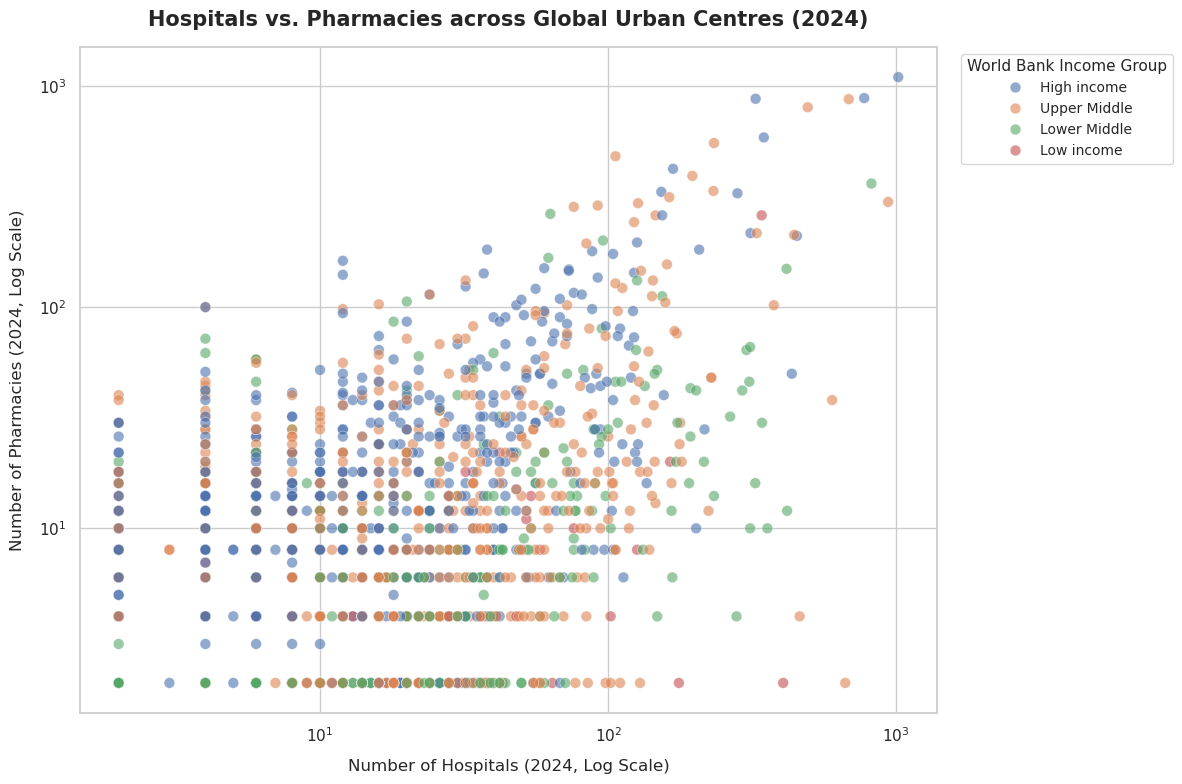

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# 1. Load the dataset directly from GitHub
url = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2026/2026-09-29/health.csv"
print("Loading dataset...")
df = pd.read_csv(url)

# 2. Data Cleaning & Filtering
# Drop missing values for key columns and keep only positive counts for log scale
cols_needed = [
    "HL_FCL_HOS_2024",
    "HL_FCL_PHA_2024",
    "GC_DEV_WIG_2025",
    "GC_UCN_MAI_2025",
]
df_clean = df.dropna(subset=cols_needed).copy()

# Filter for strictly positive counts to avoid log(0) issues
df_clean = df_clean[
    (df_clean["HL_FCL_HOS_2024"] > 0) & (df_clean["HL_FCL_PHA_2024"] > 0)
]

# 3. Set up the visualization style
sns.set_theme(style="whitegrid", palette="deep")
plt.figure(figsize=(12, 8))

# 4. Create scatter plot with income group coloring
ax = sns.scatterplot(
    data=df_clean,
    x="HL_FCL_HOS_2024",
    y="HL_FCL_PHA_2024",
    hue="GC_DEV_WIG_2025",
    alpha=0.6,
    s=60,
    edgecolor="w",
    linewidth=0.4,
)

# 5. Apply Log Scale on both axes due to wide magnitude ranges
ax.set_xscale("log")
ax.set_yscale("log")

# 6. Formatting and Titles
plt.title(
    "Hospitals vs. Pharmacies across Global Urban Centres (2024)",
    fontsize=15,
    weight="bold",
    pad=15,
)
plt.xlabel(
    "Number of Hospitals (2024, Log Scale)", fontsize=12, labelpad=10
)
plt.ylabel(
    "Number of Pharmacies (2024, Log Scale)", fontsize=12, labelpad=10
)

# Customize Legend
plt.legend(
    title="World Bank Income Group",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=True,
    fontsize=10,
    title_fontsize=11,
)

plt.tight_layout()

# 7. Save and Show
output_filename = "hospitals_vs_pharmacies_income.png"
plt.savefig(output_filename, dpi=300, bbox_inches="tight")
print(f"Chart successfully saved as '{output_filename}'!")

plt.show()